# Committor Model: 2D Brownian Dynamics on the Z Potential, Long MD (NPq)

Trains the equilibrium non-parametric committor (NPq, `optimalrcs.Committor`) on a long overdamped MD of a particle on the 2D Z potential, and compares it with the exact committor of the same dynamics.

**Data:** 16 independent long MDs from toytis `md_run.py` (`md_zbr_g10_s1` … `s16`), each a `md_path.txt` with columns `step y x vy vx`, one saved row per 20 MD steps (`--stride 20`); ~53M rows in total. The velocity columns of a Brownian (high-friction) run are noise and are not used. Alternatively, section 1b runs one long trajectory of the same dynamics in the notebook. The CVs are the two positions: y (the order parameter, along the channel) and x (transverse).

**Simulation:** Brownian dynamics (`high_friction`), γ = 10, kT = 0.05, dt = 0.002; potential `sjoelbak_angle.RectangularGridWithAngledBarrierPotential(Lx=0.3, angle=45)` with a constant force of 0.2 along −y (the effective potential includes it). The barrier is a ridge at 45°, so beyond it the committor depends on x as well as y.

**Boundaries:** A: y ≤ 0.1, B: y ≥ 0.85. A is at 0.1 rather than at the first staple interface (0.05): the exact committor is below 0.003 up to y = 0.3, so nothing changes where it matters, and the data are 3× smaller.

**Exact committor:** solved on a grid by `figures/z_brownian/committor_reference.py` for the same A, B and saved-row spacing (A/B are only detected on saved rows, which moves the effective boundaries out by 0.58 σ √20). Solved automatically if missing.

**Reference result** (`figures/z_brownian/npq_md.py`, 8000 iterations): RMS(NPq − exact) 0.048 over the bins with 0.05 < q < 0.95, against a statistical error (two halves of the seeds) of 0.027. The NPq plateau beyond the ridge sits ~0.05 above the exact committor, and so does the raw data: of the excursions that reach the plateau, 0.74 ± 0.03 end in B against an exact 0.67. That is a sampling fluctuation of the 37 transitions, not a bias of NPq.

## 1. Imports

In [1]:
import glob
import os
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp
from cupy.interpolate import RegularGridInterpolator

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package (CuPy), and the shared seed loop of the example notebooks
REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs, metrics, plots, cut_profiles
import seed_runs

# toytis, for the potential contours
SIMS = '/home/staff7/fbsskr/Notebooks/Students/elias/data'
TOYTIS = '/home/staff7/fbsskr/Notebooks/Students/elias/toytis'
sys.path.insert(0, TOYTIS)
from potentials.sjoelbak_angle import RectangularGridWithAngledBarrierPotential
potential = RectangularGridWithAngledBarrierPotential(Lx=0.3, angle=45)

# Figures of this notebook go to their own directory
FIG_DIR = f'{REPO}/examples/figures/nb_zbrownian_md'
os.makedirs(FIG_DIR, exist_ok=True)
def save_fig(name):
    plt.gcf().savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight')

ModuleNotFoundError: No module named 'cupy.interpolate'

## 1b. Optional: Run a Long MD Here

Runs one long Brownian trajectory on the Z potential right here (`RUN_MD = True`), instead of reading the 16 `md_run.py` seeds. The update is that of the toytis engine with `high_friction`: every step y, x += dt/(mγ) F + √(2 dt kT/(mγ)) N(0, 1), with the force of `sjoelbak_angle` (gravity included). The force is checked against `potential.potential_and_force` at 4000 random points before the run.

The loop is compiled C (`gcc`, called through `ctypes`): ~35M steps/s, so the 10⁹ steps of the 16 seeds together take about 30 s. One saved row (y, x) every `MD_STRIDE` steps is written to `MD_OUT` (`.npy`, float32) as the run goes; section 2 then reads this file (one trajectory). With `RUN_MD = False` an existing `MD_OUT` is reused if `USE_NB_MD = True`, otherwise section 2 reads the `md_run.py` seeds.

Expected number of A→B transitions: about one per 4.3·10⁷ steps (GPU walkers; the PDE gives 4.4·10⁷), so 10⁹ steps give ~25 ± 5.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `RUN_MD` | False | Run the MD now (overwrites `MD_OUT`) |
| `USE_NB_MD` | False | Read `MD_OUT` in section 2 instead of the `md_run.py` seeds |
| `MD_STEPS` | 1.06·10⁹ | MD steps (the 16 seeds together) |
| `MD_STRIDE` | 20 | Steps per saved row (also the `STRIDE` of the reference committor) |
| `MD_SEED` | 0 | Random seed |
| `MD_START` | (0.03, 0.15) | Start point (y, x), in A, as `md_run.py` |
| `MD_DT`, `MD_GAMMA`, `MD_KT` | 0.002, 10, 0.05 | Time step, friction, temperature (mass 1) |

In [ ]:
import ctypes
import tempfile
import time

RUN_MD = False                     # run the MD now (overwrites MD_OUT)
USE_NB_MD = False                  # section 2 reads MD_OUT instead of the md_run.py seeds
MD_STEPS = 1_060_000_000           # MD steps
MD_STRIDE = 20                     # steps per saved row
MD_SEED = 0
MD_START = (0.03, 0.15)            # (y, x)
MD_DT, MD_GAMMA, MD_KT = 0.002, 10.0, 0.05
MD_OUT = f'{FIG_DIR}/md_nb_seed{MD_SEED}_steps{MD_STEPS:.2e}_stride{MD_STRIDE}.npy'


def compile_md(p):
    """Compile the Brownian integrator for potential p (sjoelbak_angle); returns the ctypes library."""
    c = dict(LX=p.Lx, LY=p.Ly, K=p.k, A=p.A, L=p.L, R=p.r, B=p.b, NORM=np.sqrt(p.r ** 2 + 1),
             Y0=p.state_y[0], Y1=p.state_y[1], AM0=p.state_A[0], AM1=p.state_A[1],
             EL0=p.state_L[0], EL1=p.state_L[1], G=p.gravity, S0=p.slope_start_y, S1=p.slope_end_y,
             SS=p.slope_strength_y)
    src = '\n'.join(f'#define {k} ({float(v)!r})' for k, v in c.items()) + r"""
#include <math.h>
#include <stdint.h>
#define PI 3.141592653589793
/* force of sjoelbak_angle.potential_and_force, positions (y, x) */
static void force(double y, double x, double* fy, double* fx) {
    double gy = 0.0, gx = 0.0;
    if (x < 0) gx = -K * x; else if (x > LX) gx = -K * (x - LX);              /* walls */
    if (y < 0) gy = -K * y; else if (y > LY) gy = -K * (y - LY);
    double D = fabs(R * x - y + B) / NORM;                                     /* tilted cosine ridge */
    if (D < L / 4) {
        double s = y - R * x - B, dsgn = (s > 0) - (s < 0);
        double dV = -2 * PI * A / L * sin(2 * PI * D / L);
        gx += dsgn * dV * R / NORM; gy += dsgn * dV * (-1.0 / NORM);
    }
    double Ds = fabs(y - Y0);                                                  /* state wells */
    if (Ds < EL0 / 4) gy += AM0 * 2 * PI / EL0 * sin(2 * PI * Ds / EL0) * ((y > Y0) - (y < Y0));
    Ds = fabs(y - Y1);
    if (Ds < EL1 / 4) gy += AM1 * 2 * PI / EL1 * sin(2 * PI * Ds / EL1) * ((y > Y1) - (y < Y1));
    gy -= G;                                                                   /* gravity */
    if (y >= S0 && y <= S1) gy += -SS / (S1 - S0);                             /* global slope */
    *fy = gy; *fx = gx;
}
void check_force(const double* y, const double* x, double* f, long n) {
    for (long i = 0; i < n; i++) force(y[i], x[i], &f[2 * i], &f[2 * i + 1]);
}
/* xoshiro256+ uniforms, polar Box-Muller normals */
static inline uint64_t rotl(uint64_t v, int k) { return (v << k) | (v >> (64 - k)); }
static double uniform(uint64_t* s) {
    uint64_t r = s[0] + s[3], t = s[1] << 17;
    s[2] ^= s[0]; s[3] ^= s[1]; s[1] ^= s[2]; s[0] ^= s[3]; s[2] ^= t; s[3] = rotl(s[3], 45);
    return (r >> 11) * 0x1.0p-53;
}
static void normal2(uint64_t* s, double* a, double* b) {
    double u, v, q;
    do { u = 2 * uniform(s) - 1; v = 2 * uniform(s) - 1; q = u * u + v * v; } while (q >= 1 || q == 0);
    q = sqrt(-2 * log(q) / q); *a = u * q; *b = v * q;
}
/* n_steps steps y, x += bddt F + sigma N(0, 1); (y, x) saved every stride steps into out.
   state (y, x), rng (4 x uint64) and *step carry over between calls. Returns the rows written. */
long run(double* state, uint64_t* rng, long long* step, long long n_steps, int stride,
         double bddt, double sigma, float* out) {
    double y = state[0], x = state[1]; long long st = *step; long k = 0;
    for (long long i = 0; i < n_steps; i++) {
        double fy, fx, ny, nx;
        force(y, x, &fy, &fx); normal2(rng, &ny, &nx);
        y += bddt * fy + sigma * ny; x += bddt * fx + sigma * nx;
        if (++st % stride == 0) { out[2 * k] = (float)y; out[2 * k + 1] = (float)x; k++; }
    }
    state[0] = y; state[1] = x; *step = st; return k;
}
"""
    d = tempfile.mkdtemp()
    with open(f'{d}/md.c', 'w') as f:
        f.write(src)
    subprocess.run(['gcc', '-O3', '-march=native', '-shared', '-fPIC', '-o', f'{d}/md.so', f'{d}/md.c', '-lm'],
                   check=True)
    lib = ctypes.CDLL(f'{d}/md.so')
    P = ctypes.POINTER
    lib.check_force.argtypes = [P(ctypes.c_double), P(ctypes.c_double), P(ctypes.c_double), ctypes.c_long]
    lib.run.restype = ctypes.c_long
    lib.run.argtypes = [P(ctypes.c_double), P(ctypes.c_uint64), P(ctypes.c_longlong), ctypes.c_longlong,
                        ctypes.c_int, ctypes.c_double, ctypes.c_double, P(ctypes.c_float)]
    return lib


def ptr(a, ctype):
    return a.ctypes.data_as(ctypes.POINTER(ctype))


if RUN_MD:
    lib = compile_md(potential)
    # the compiled force against the toytis potential
    pts = np.random.default_rng(1).uniform((-0.05, -0.05), (0.95, 0.35), (4000, 2))
    f = np.zeros(2 * len(pts))
    lib.check_force(ptr(np.ascontiguousarray(pts[:, 0]), ctypes.c_double),
                    ptr(np.ascontiguousarray(pts[:, 1]), ctypes.c_double), ptr(f, ctypes.c_double), len(pts))
    f_ref = np.array([potential.potential_and_force((pt, np.zeros(2)))[1] for pt in pts])
    assert np.allclose(f.reshape(-1, 2), f_ref, atol=1e-9), 'compiled force differs from the potential'

    n_rows = MD_STEPS // MD_STRIDE
    out = np.lib.format.open_memmap(MD_OUT, mode='w+', dtype=np.float32, shape=(n_rows, 2))
    state = np.array(MD_START, dtype=np.float64)
    rng_state = np.random.SeedSequence(MD_SEED).generate_state(4, np.uint64)
    step = ctypes.c_longlong(0)
    bddt, sigma = MD_DT / MD_GAMMA, np.sqrt(2 * MD_DT * MD_KT / MD_GAMMA)
    rows_per_call = 2_500_000                       # 5e7 steps per call at stride 20
    side, n_ab, done, t0 = 0, 0, 0, time.time()     # side: last state visited (0 A, 1 B), for counting A->B
    while done < n_rows:
        n = min(rows_per_call, n_rows - done)
        buf = np.empty((n, 2), np.float32)
        lib.run(ptr(state, ctypes.c_double), ptr(rng_state, ctypes.c_uint64), ctypes.byref(step),
                n * MD_STRIDE, MD_STRIDE, bddt, sigma, ptr(buf, ctypes.c_float))
        out[done:done + n] = buf
        lab = np.where(buf[:, 0] <= 0.1, 0, np.where(buf[:, 0] >= 0.85, 1, -1))   # 0: in A, 1: in B
        lab = np.r_[side, lab[lab >= 0]]
        n_ab += int(((lab[:-1] == 0) & (lab[1:] == 1)).sum()); side = lab[-1]
        done += n
        if done == n_rows or (done // rows_per_call) % 4 == 0:
            el = time.time() - t0
            print(f'{done * MD_STRIDE:.3e} / {MD_STEPS:.3e} steps ({el:.0f} s, {done * MD_STRIDE / el / 1e6:.0f}M steps/s): '
                  f'{n_ab} A->B transitions (A: y <= 0.1, B: y >= 0.85)', flush=True)
    out.flush(); del out
    print(f'saved {MD_OUT}')
if RUN_MD or USE_NB_MD:
    print(f'section 2 reads {MD_OUT}')

## 2. Data Loading

Reads every `md_path.txt` in chunks (two columns: y, x), or the trajectory of section 1b (`RUN_MD` or `USE_NB_MD`). Per seed the first `BURN_IN` saved rows are dropped (relaxation from the start point, all seeds start at (0.15, 0.03)).

**Excursions only.** The particle spends >99% of the time in A. Only the rows outside A and B are kept, together with the A/B row right before and after each excursion, and every excursion becomes its own trajectory segment. For NPq this loses nothing: a step between two rows inside the same state has a fixed committor (0 or 1) and adds nothing to the fit. It reduces ~53M rows to ~4.6M, which fits on the 8 GB GPU.

A 2D histogram of all rows (not only the kept ones) is kept for the free energy surface. The kept rows are cached in `FIG_DIR` (keyed by the settings), so a rerun skips the ~30 s read.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `LAMBDA_A`, `LAMBDA_B` | 0.1, 0.85 | A: y ≤ `LAMBDA_A`, B: y ≥ `LAMBDA_B` |
| `BURN_IN` | 5000 | Saved rows dropped at the start of every seed |
| `STRIDE` | 20 | MD steps per saved row (`md_run --stride`), for the reference committor |
| `SEEDS_MD` | 1..16 | Which MD seeds to read |

In [7]:
MD_GLOB = f'{SIMS}/simulations/md_zbr_g10_s*/md_path.txt'
SEEDS_MD = list(range(1, 17))      # MD seeds to read
LAMBDA_A, LAMBDA_B = 0.1, 0.85     # A: y <= LAMBDA_A, B: y >= LAMBDA_B
BURN_IN = 1_000                    # saved rows dropped per seed
STRIDE = 20                        # MD steps per saved row
CHUNK_ROWS = 10_000_000             # rows per read chunk
E_Y, E_X = np.linspace(-0.01, 0.91, 93), np.linspace(-0.01, 0.31, 33)   # histogram bins (all rows)

if RUN_MD or USE_NB_MD:              # the trajectory of section 1b
    SEEDS_MD, FILES = [1], [MD_OUT]
    STRIDE = MD_STRIDE
else:
    files = {int(p.split('_s')[-1].split('/')[0]): p for p in glob.glob(MD_GLOB)}
    FILES = [files[s] for s in SEEDS_MD]


def read_chunks(path):
    # (y, x) rows of one MD file in chunks: md_run.py md_path.txt (columns step y x vy vx) or a (rows, 2) .npy
    if path.endswith('.npy'):
        a = np.load(path, mmap_mode='r')
        for s0 in range(0, len(a), CHUNK_ROWS):
            yield np.asarray(a[s0:s0 + CHUNK_ROWS], dtype=np.float64)
    else:
        for df in pd.read_csv(path, sep=r'\s+', comment='#', header=None, usecols=[1, 2],
                              chunksize=CHUNK_ROWS, dtype=np.float64):
            yield df.to_numpy()


def load(path):
    # kept rows (y, x) of one seed, their row indices, and the 2D histogram of all rows after burn-in
    kept, kept_idx, hist = [], [], np.zeros((len(E_Y) - 1, len(E_X) - 1))
    pending, start = None, 0       # pending: last row of the previous chunk (its right neighbour is unread)
    for rows in read_chunks(path):
        idx = np.arange(start, start + len(rows)); start += len(rows)
        sel = idx >= BURN_IN; rows, idx = rows[sel], idx[sel]
        if len(idx) == 0:
            continue
        hist += np.histogram2d(rows[:, 0], rows[:, 1], [E_Y, E_X])[0]
        out = (rows[:, 0] > LAMBDA_A) & (rows[:, 0] < LAMBDA_B)
        left_of_first = False
        if pending is not None:
            rows, idx = np.vstack([pending[0], rows]), np.r_[pending[1], idx]
            left_of_first, out = pending[3], np.r_[pending[2], out]
        keep = out | np.r_[left_of_first, out[:-1]] | np.r_[out[1:], False]
        kept.append(rows[:-1][keep[:-1]]); kept_idx.append(idx[:-1][keep[:-1]])
        pending = (rows[-1:], idx[-1:], out[-1:], bool(out[-2]) if len(out) > 1 else left_of_first)
    if pending is not None and (pending[2][0] or pending[3]):
        kept.append(pending[0]); kept_idx.append(pending[1])
    return np.concatenate(kept), np.concatenate(kept_idx), hist


src_tag = os.path.splitext(os.path.basename(MD_OUT))[0] if (RUN_MD or USE_NB_MD) else \
          f'seeds{SEEDS_MD[0]}-{SEEDS_MD[-1]}_n{len(SEEDS_MD)}'
cache = f'{FIG_DIR}/kept_rows_A{LAMBDA_A}_B{LAMBDA_B}_burn{BURN_IN}_{src_tag}.npz'
if RUN_MD and os.path.exists(cache):
    os.remove(cache)               # a new MD: read it again
if os.path.exists(cache):
    d = np.load(cache)
    Z, row, seed_md, hist_all = d['Z'], d['row'], d['seed'], d['hist']
    print(f'Loaded {cache}')
else:
    Z, row, seed_md, hist_all = [], [], [], 0
    for s, path in zip(SEEDS_MD, FILES):
        z, r, h = load(path)
        Z.append(z); row.append(r); seed_md.append(np.full(len(r), s)); hist_all = hist_all + h
        print(f'seed {s}: {int(h.sum())} rows after burn-in, kept {len(r)}')
    Z, row, seed_md = np.concatenate(Z), np.concatenate(row), np.concatenate(seed_md)
    np.savez(cache, Z=Z, row=row, seed=seed_md, hist=hist_all)

lam, xpos = Z[:, 0], Z[:, 1]       # lambda = y (order parameter), x
print(f'{int(hist_all.sum())} rows after burn-in, kept {len(lam)} ({len(lam) / hist_all.sum():.1%})')

seed 1: 4976060 rows after burn-in, kept 431878
seed 2: 3781818 rows after burn-in, kept 323770
seed 3: 3682263 rows after burn-in, kept 326170
seed 4: 4378947 rows after burn-in, kept 370383
seed 5: 4279312 rows after burn-in, kept 370851
seed 6: 1890428 rows after burn-in, kept 169294
seed 7: 1989962 rows after burn-in, kept 162716
seed 8: 2786195 rows after burn-in, kept 237075
seed 9: 3881304 rows after burn-in, kept 363634
seed 10: 2587316 rows after burn-in, kept 219714
seed 11: 1989799 rows after burn-in, kept 184861
seed 12: 4179899 rows after burn-in, kept 361467
seed 13: 4179884 rows after burn-in, kept 354917
seed 14: 1989949 rows after burn-in, kept 174333
seed 15: 4378929 rows after burn-in, kept 384113
seed 16: 2089583 rows after burn-in, kept 184256
53041648 rows after burn-in, kept 4619432 (8.7%)


## 3. Free Energy Surface

Equilibrium F(y, x) = −kT ln p from all rows after burn-in, in units of kT, and F along y. A sits at the bottom of the channel (y < 0.1), the 45° ridge separates it from the plateau, and B is ~7 kT above A, so B is rarely visited and the free energy there is noisy.

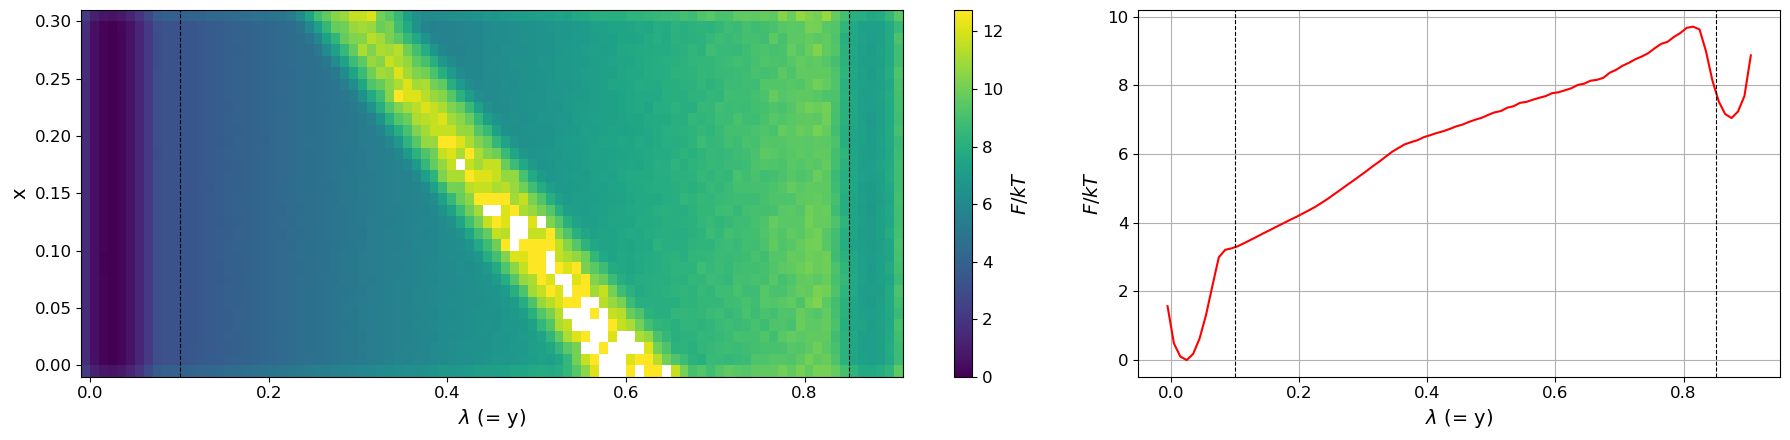

In [8]:
p = hist_all / hist_all.sum()
F2 = np.where(p > 0, -np.log(np.where(p > 0, p, 1)), np.nan)
F2 -= np.nanmin(F2)
p_y = hist_all.sum(1); m_y = (E_Y[1:] + E_Y[:-1]) / 2
F1 = -np.log(np.where(p_y > 0, p_y / p_y.sum(), np.nan)); F1 -= np.nanmin(F1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
im = ax1.pcolormesh(E_Y, E_X, F2.T, cmap='viridis', vmax=np.nanpercentile(F2, 99))
fig.colorbar(im, ax=ax1, label='$F/kT$')
ax2.plot(m_y, F1, 'r-')
for ax in (ax1, ax2):
    for lb in (LAMBDA_A, LAMBDA_B):
        ax.axvline(lb, color='k', ls='--', lw=0.8)
ax1.set(xlabel='$\\lambda$ (= y)', ylabel='x')
ax2.set(xlabel='$\\lambda$ (= y)', ylabel='$F/kT$'); ax2.grid()
plt.tight_layout()
save_fig('free_energy')
plt.show()

## 4. Trajectory Indices and Exact Committor

Every excursion is its own segment: a new segment starts where two kept rows are not consecutive in the same seed. `t_traj` is the saved-row index within its seed.

`N_AB` counts the A→B transitions: consecutive A/B visits within a seed that go from A to B. For the committor, Z_q(q, Δt) converges to `N_AB` at every q and lag (notes §8.1).

The exact committor of the same dynamics, A, B and row spacing is interpolated at every kept row (`q_ref`), for the comparisons below; it is not used in training.

In [9]:
in_a, in_b = lam <= LAMBDA_A, lam >= LAMBDA_B
new_segment = np.r_[True, (seed_md[1:] != seed_md[:-1]) | (np.diff(row) != 1)]
i_traj = np.cumsum(new_segment)    # excursion index
t_traj = row.astype(np.float64)    # saved-row index within its seed
ab = np.flatnonzero(in_a | in_b)
same = seed_md[ab][1:] == seed_md[ab][:-1]
N_AB = int((same & in_a[ab][:-1] & in_b[ab][1:]).sum())
N_BA = int((same & in_b[ab][:-1] & in_a[ab][1:]).sum())
print(f'Rows: {len(lam)}, excursions: {i_traj[-1]}, rows in A: {in_a.sum()}, in B: {in_b.sum()}')
print(f'A->B transitions: {N_AB}, B->A: {N_BA}')

# exact committor, solved on a grid for the same A, B and stride (a few minutes the first time)
ZDIR = f'{REPO}/examples/figures/z_brownian'
ref_file = f'{ZDIR}/committor_reference_h0.001_A{LAMBDA_A}_B{LAMBDA_B}_s{STRIDE}.npz'
if not os.path.exists(ref_file):
    env = dict(os.environ, GRID_H='0.001', LAMBDA_A=str(LAMBDA_A), LAMBDA_B=str(LAMBDA_B),
               STRIDE=str(STRIDE), SKIP_SHOOTING='1')
    subprocess.run([sys.executable, f'{ZDIR}/committor_reference.py'], env=env, check=True)
ref = np.load(ref_file)
q_ref = np.clip(RegularGridInterpolator((ref['y'], ref['x']), ref['q'], bounds_error=False,
                                        fill_value=None)(Z), 0, 1)
q_ref[in_a], q_ref[in_b] = 0, 1
print(f'Exact committor: {ref_file}')

Rows: 4619432, excursions: 205784, rows in A: 551834, in B: 5587
A->B transitions: 37, B->A: 37
Exact committor: /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/z_brownian/committor_reference_h0.001_A0.1_B0.85_s20.npz


## 5. Train Committor (NPq)

`optimalrcs.Committor`: the data are an equilibrium trajectory of reversible (Brownian) dynamics, and the CVs (y, x) are the full state, so the equilibrium estimator applies and no history is needed. Each iteration draws y or x as the observed variable.

Every excursion starts and ends in A or B, so `set_boundary_traps()` treats those segment edges as staying in the state: the Z_q plots (`feps`) then equal those of the continuous trajectories (notes §8.1). It changes the metrics and plots only, not the fit.

**Parameters** (as `figures/z_brownian/npq_md.py`):
| Parameter | Value | Description |
|-----------|-------|-------------|
| `ENVELOPE` | 0.01 | RC envelope width (`envelope_scale`, the library default) |
| `GAMMA` | 0 | Regularization |
| `ny` | 6 | Polynomial degree |
| `MAX_ITER` | 4000 | Iterations per seed; in the reference run `\|dx\|` reached ~1e-5 by ~3000 (~0.27 s per iteration on 4.6M rows) |

**Seeds and warm-up** (`seed_runs.run_seeds`, shared with the other notebooks): the fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). The first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV (`WARMUP_CV`: `None` random, 0 = y, 1 = x); then `ENVELOPE` and `GAMMA` take over (`WARMUP_ITER = 0`: no warm-up). After the warm-up and every `CHUNK` iterations the plots in `PLOTS` are shown here and saved to `<FIG_DIR>/seeds/seed<s>/it<N>_<plot>.png`, with a progress line.

**Committor map per chunk** (`seed_runs.committor_map` with the exact committor): mean q per (y, x) bin on the effective potential: fit, exact, and fit − exact with its RMS over the bins where 0.05 < q_exact < 0.95. Saved as `it<N>_q_map.png`.

#=0, dr2=203.386, sdzq=19.0572, auc=0.98832, |dx|=0.461631, time=1.07783
#=500, dr2=63.7046, sdzq=1.49306, auc=0.990703, |dx|=0.117546, time=20.5181
#=1000, dr2=63.3465, sdzq=1.44268, auc=0.99071, |dx|=0.000198949, time=39.9892
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/nb_zbrownian_md/seeds/seed6/it1000 ---


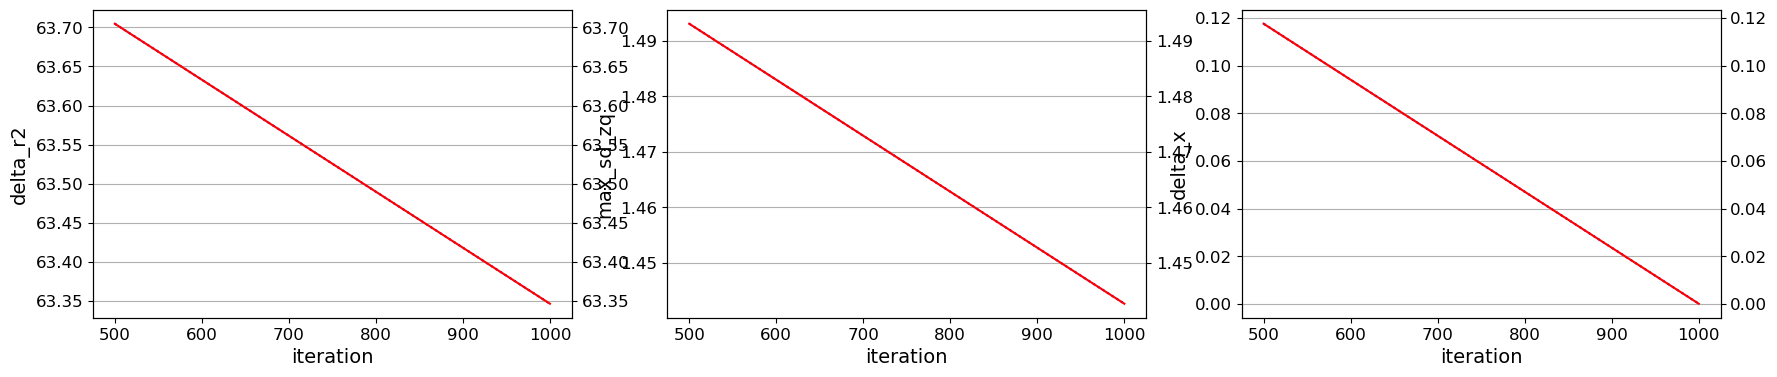

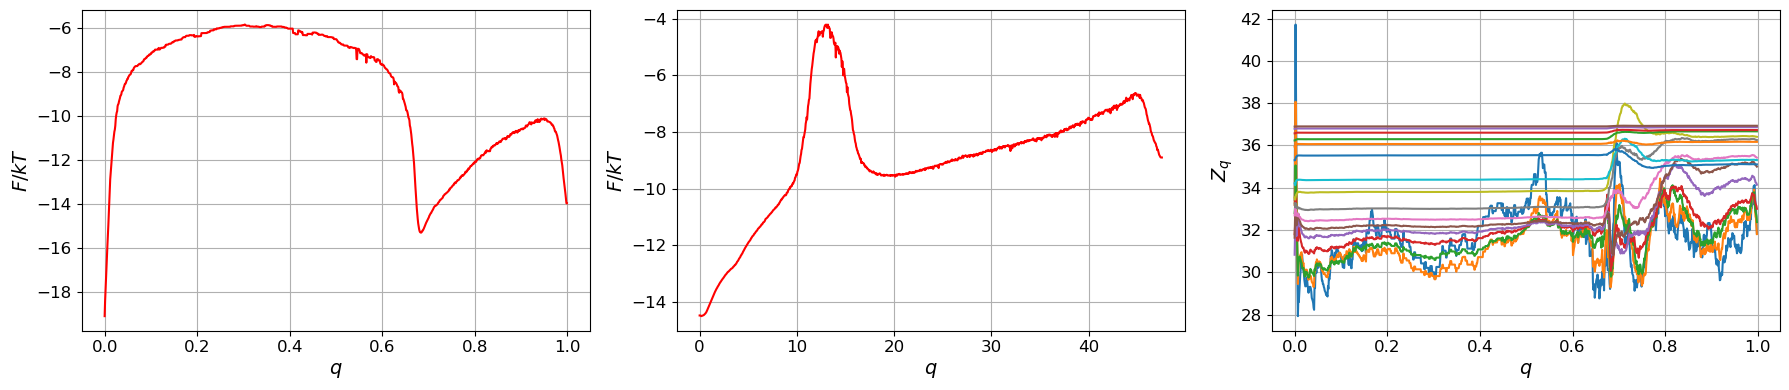

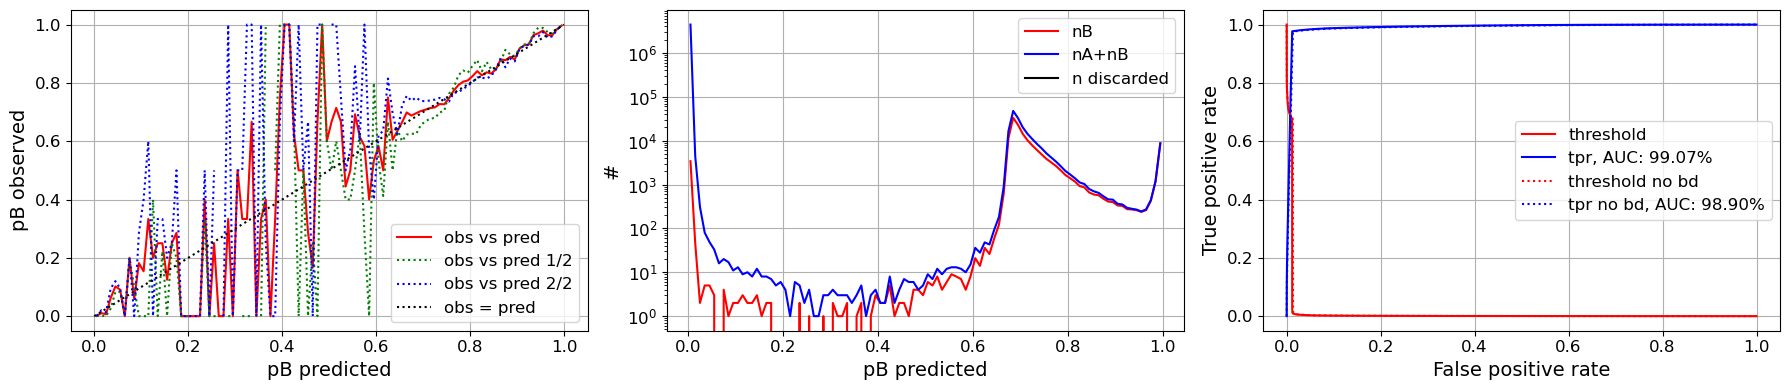

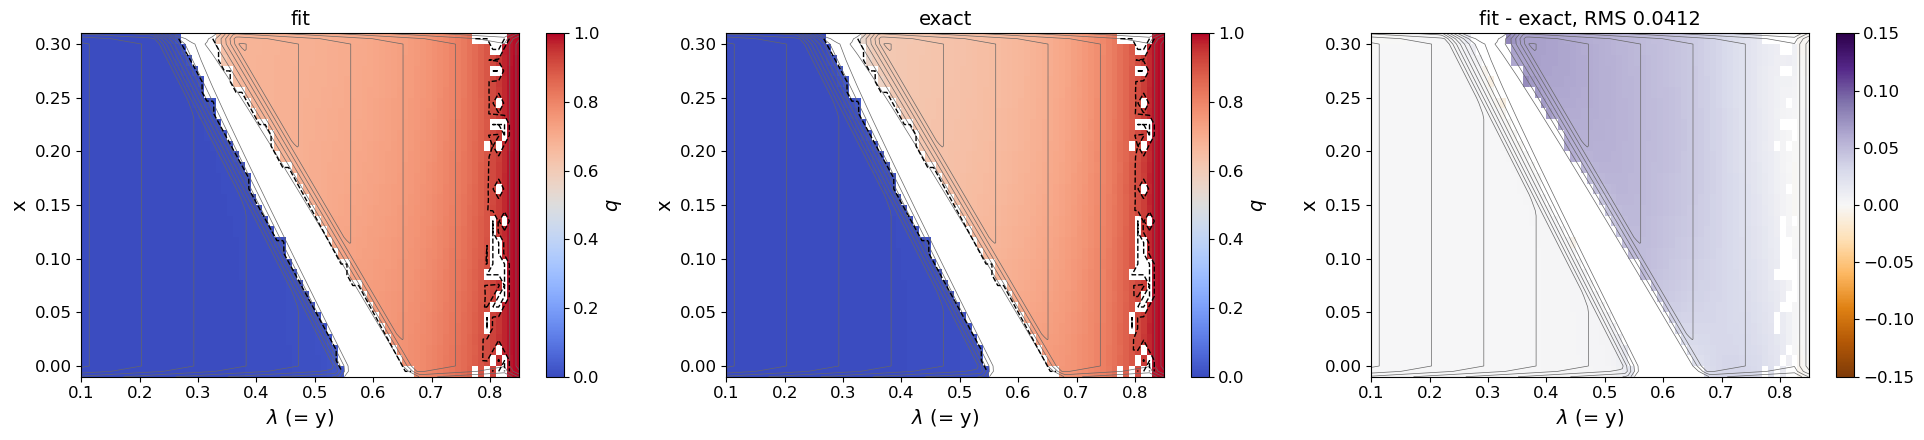

seed 6, 1000 iterations (warm-up: envelope 1, gamma 0.1) | RMS(fit - exact) per row, 0.05 < q_exact < 0.95: 0.0527
#=0, dr2=63.3437, sdzq=1.43056, auc=0.990646, |dx|=4.04088e-05, time=1.14291
#=500, dr2=62.4923, sdzq=1.27177, auc=0.990723, |dx|=0.000480682, time=20.6248
#=1000, dr2=61.644, sdzq=1.07149, auc=0.990718, |dx|=0.000718282, time=40.1158
#=1500, dr2=61.5985, sdzq=1.06035, auc=0.990721, |dx|=7.33126e-05, time=59.6042
#=2000, dr2=61.5141, sdzq=1.0237, auc=0.990723, |dx|=0.000116856, time=79.1023
#=2500, dr2=61.3169, sdzq=0.990098, auc=0.990716, |dx|=0.000218268, time=98.5904
#=3000, dr2=61.3006, sdzq=0.99247, auc=0.990722, |dx|=3.48307e-05, time=118.082
#=3500, dr2=61.2741, sdzq=0.991286, auc=0.990722, |dx|=4.06163e-05, time=137.567
#=4000, dr2=61.2644, sdzq=0.99592, auc=0.990722, |dx|=1.68407e-05, time=157.052
#=4500, dr2=61.2223, sdzq=0.977926, auc=0.990724, |dx|=5.75314e-05, time=176.491
#=5000, dr2=61.1794, sdzq=0.960335, auc=0.990719, |dx|=7.71794e-05, time=195.933
--- /ho

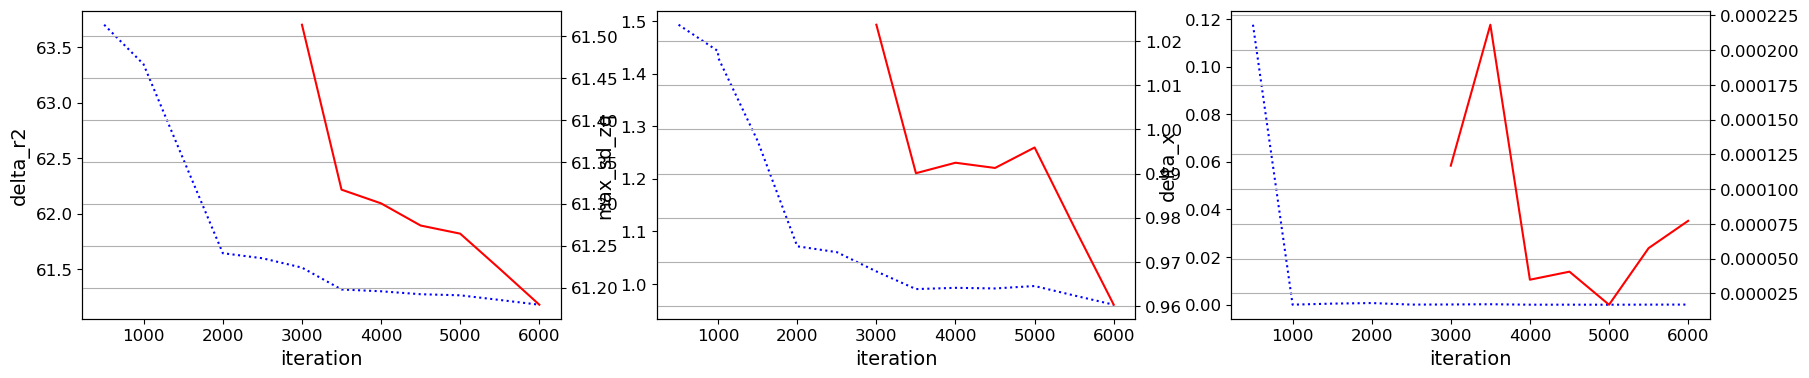

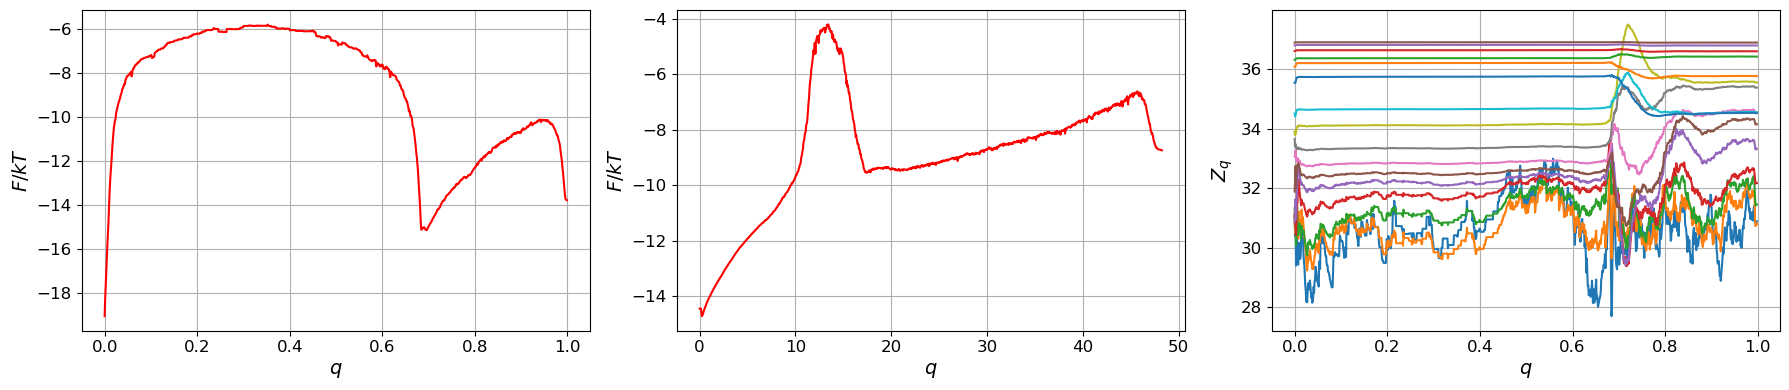

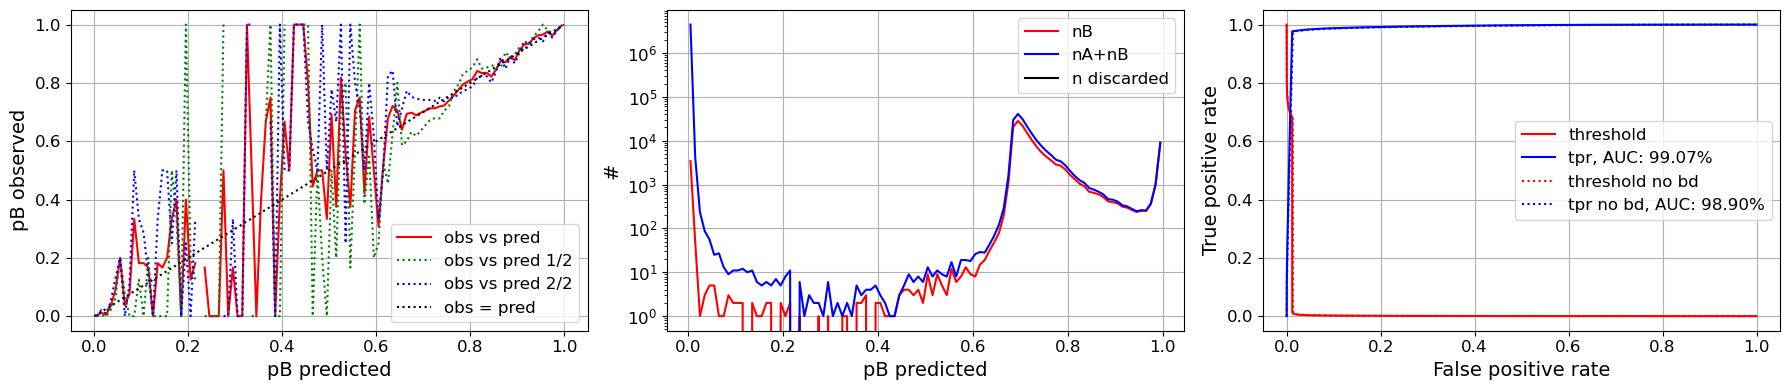

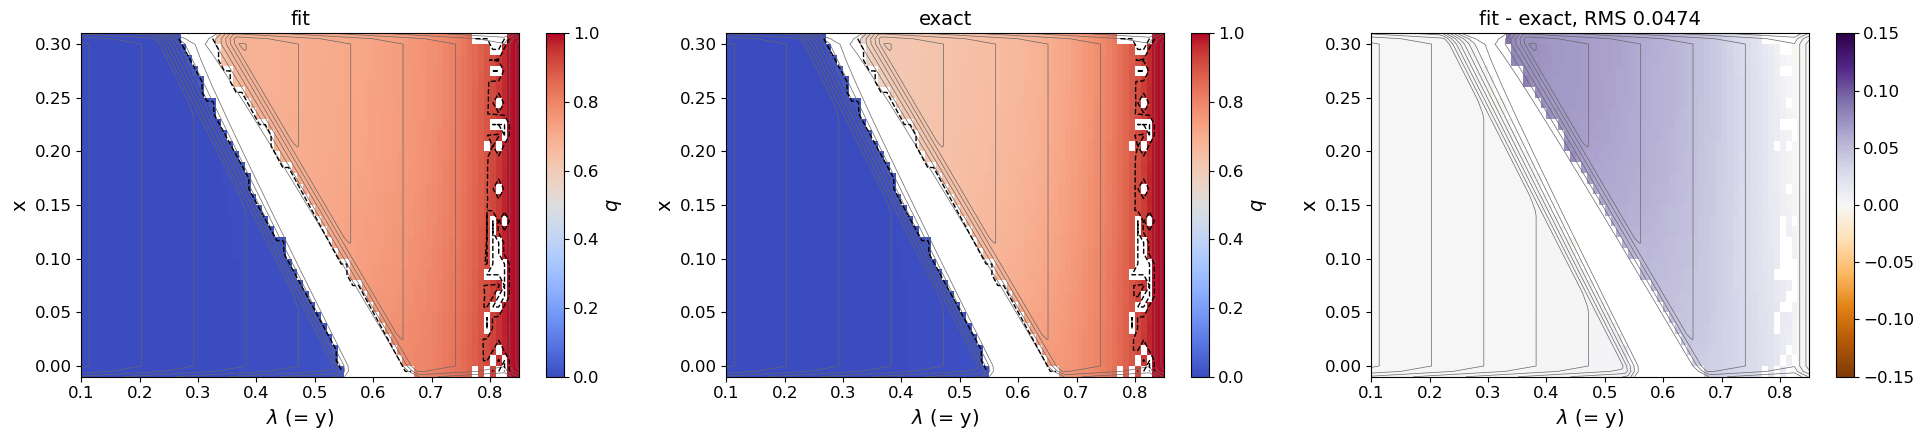

seed 6, 6000 iterations (main: envelope 0.001, gamma 0.1) | RMS(fit - exact) per row, 0.05 < q_exact < 0.95: 0.0598
#=0, dr2=61.1793, sdzq=0.960125, auc=0.99072, |dx|=9.27642e-06, time=1.15255
#=500, dr2=61.1362, sdzq=0.952851, auc=0.990719, |dx|=6.32908e-05, time=20.6029
#=1000, dr2=61.1209, sdzq=0.952062, auc=0.990721, |dx|=4.14814e-05, time=40.0472
#=1500, dr2=61.1118, sdzq=0.958447, auc=0.990721, |dx|=2.75356e-05, time=59.4844
#=2000, dr2=61.075, sdzq=0.954484, auc=0.990715, |dx|=5.74376e-05, time=78.9225
#=2500, dr2=61.0082, sdzq=0.984312, auc=0.990717, |dx|=8.09841e-05, time=98.3657
#=3000, dr2=61.0033, sdzq=0.983018, auc=0.990721, |dx|=2.11467e-05, time=117.808
#=3500, dr2=60.9973, sdzq=0.990126, auc=0.990721, |dx|=2.22091e-05, time=137.243
#=4000, dr2=60.9957, sdzq=0.991512, auc=0.990722, |dx|=1.11004e-05, time=156.681
#=4500, dr2=60.9821, sdzq=0.9815, auc=0.990722, |dx|=3.97811e-05, time=176.118
#=5000, dr2=60.9675, sdzq=0.988425, auc=0.990726, |dx|=4.57873e-05, time=195.559
-

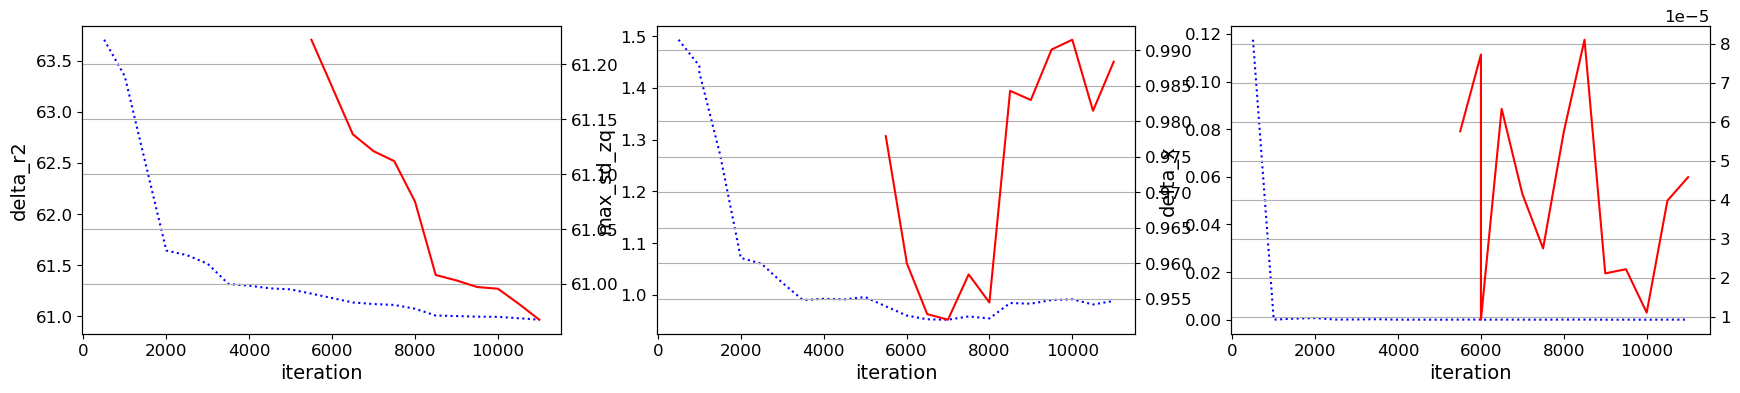

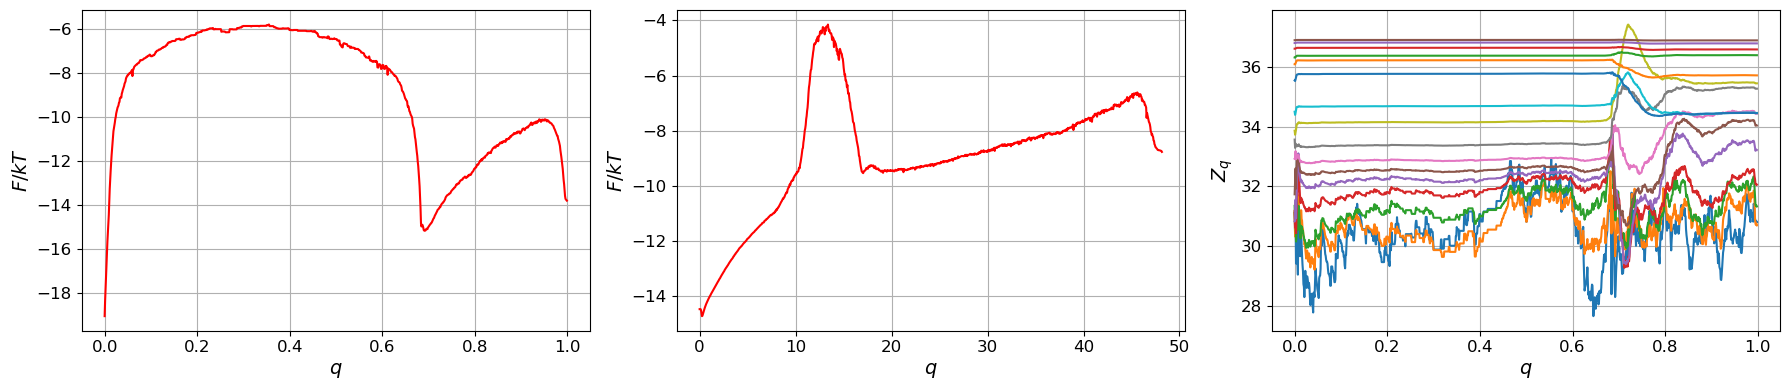

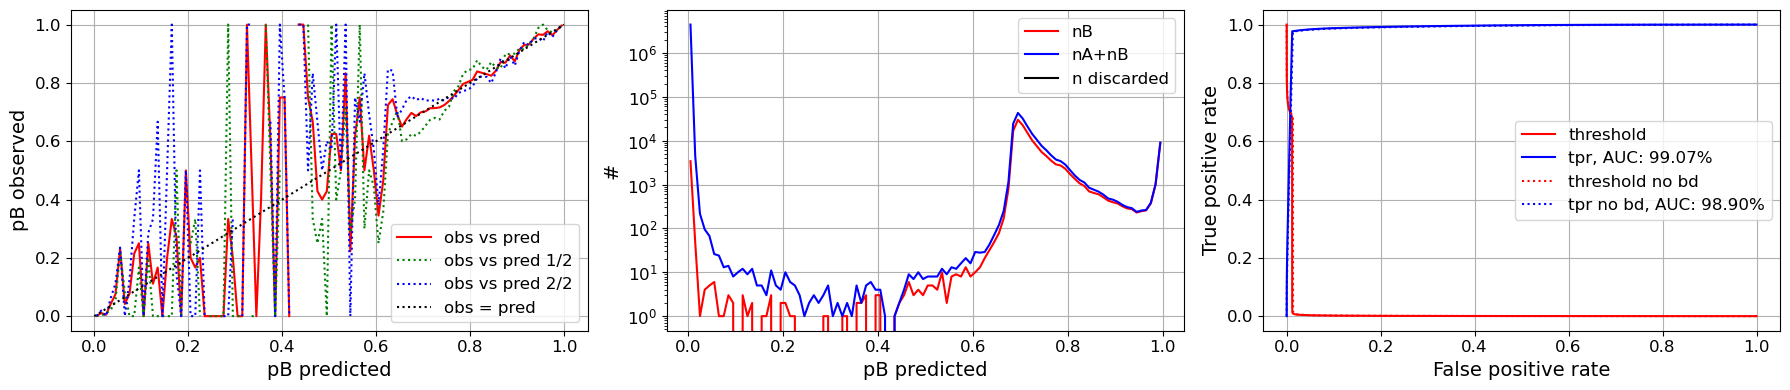

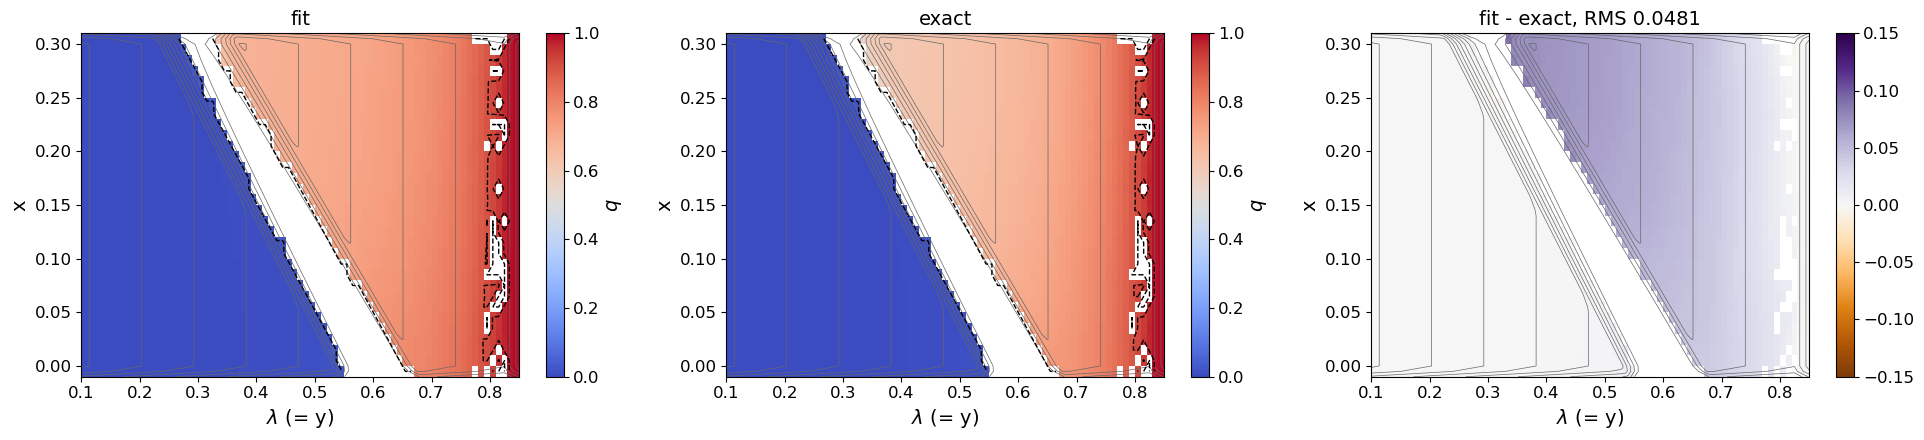

seed 6, 11000 iterations (main: envelope 0.001, gamma 0.1) | RMS(fit - exact) per row, 0.05 < q_exact < 0.95: 0.0606
#=0, dr2=60.9674, sdzq=0.988385, auc=0.990716, |dx|=1.61126e-05, time=1.14817
#=500, dr2=60.9419, sdzq=0.998776, auc=0.990721, |dx|=3.98681e-05, time=20.5853
#=1000, dr2=60.9005, sdzq=1.01458, auc=0.990723, |dx|=4.86577e-05, time=40.0358
#=1500, dr2=60.7344, sdzq=1.05698, auc=0.990724, |dx|=0.000184388, time=59.4879
#=2000, dr2=60.7303, sdzq=1.05695, auc=0.990727, |dx|=2.69164e-05, time=78.9344
#=2500, dr2=60.7108, sdzq=1.0463, auc=0.990722, |dx|=4.30935e-05, time=98.3778
#=3000, dr2=60.7032, sdzq=1.04108, auc=0.990722, |dx|=2.02546e-05, time=117.82
#=3500, dr2=60.6778, sdzq=1.03268, auc=0.990721, |dx|=4.85308e-05, time=137.265
#=4000, dr2=60.6598, sdzq=1.03004, auc=0.990729, |dx|=4.4348e-05, time=156.709
#=4500, dr2=60.6586, sdzq=1.03134, auc=0.990726, |dx|=1.2828e-05, time=176.145
#=5000, dr2=60.6452, sdzq=1.0258, auc=0.990724, |dx|=3.75865e-05, time=195.586
--- /home/

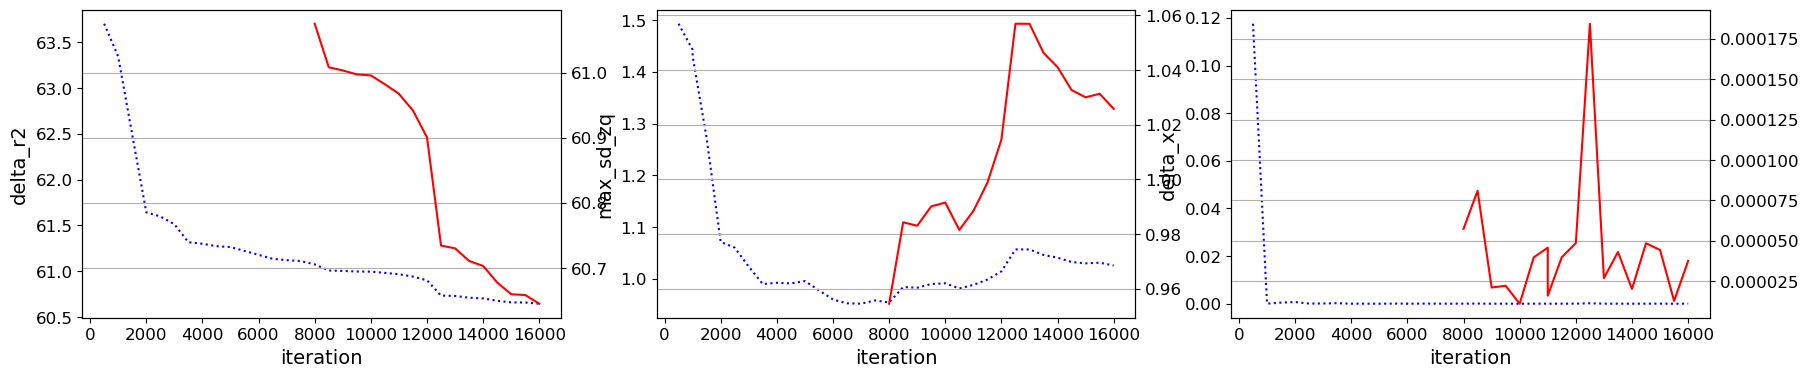

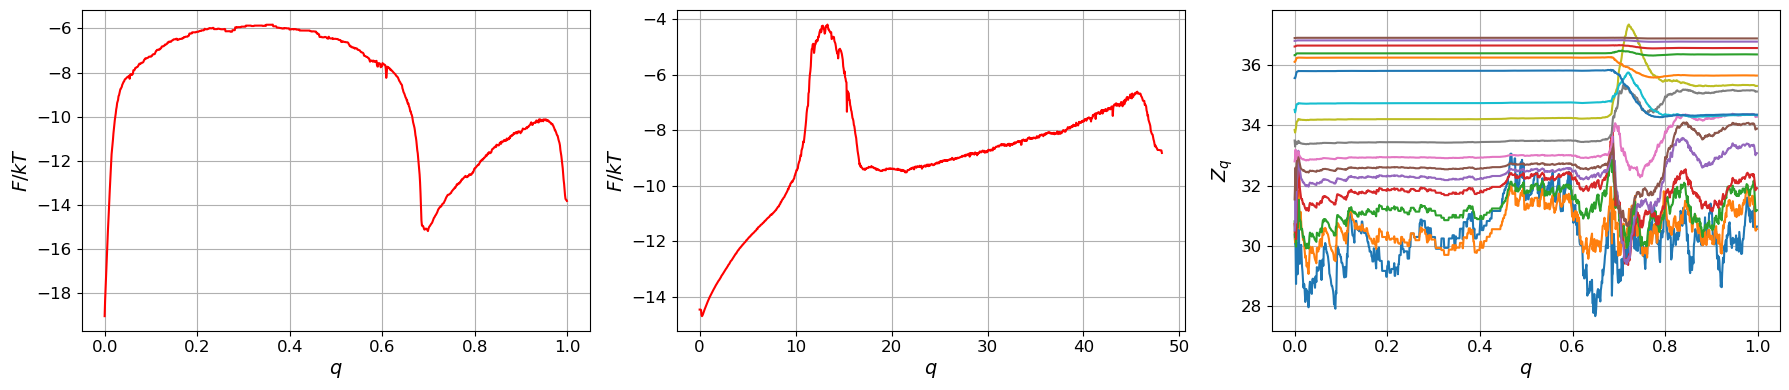

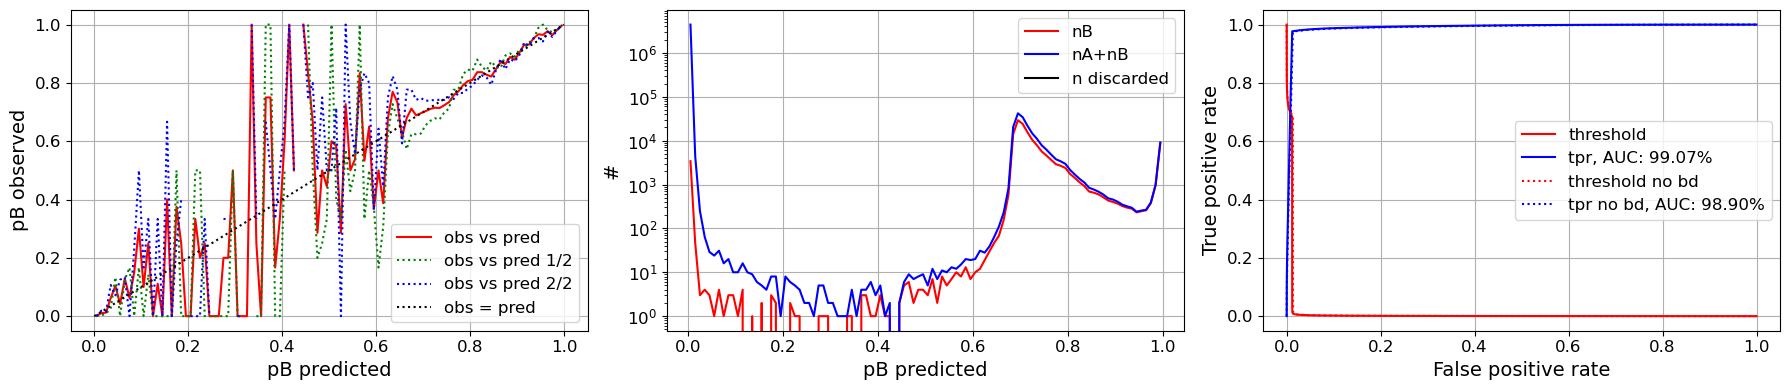

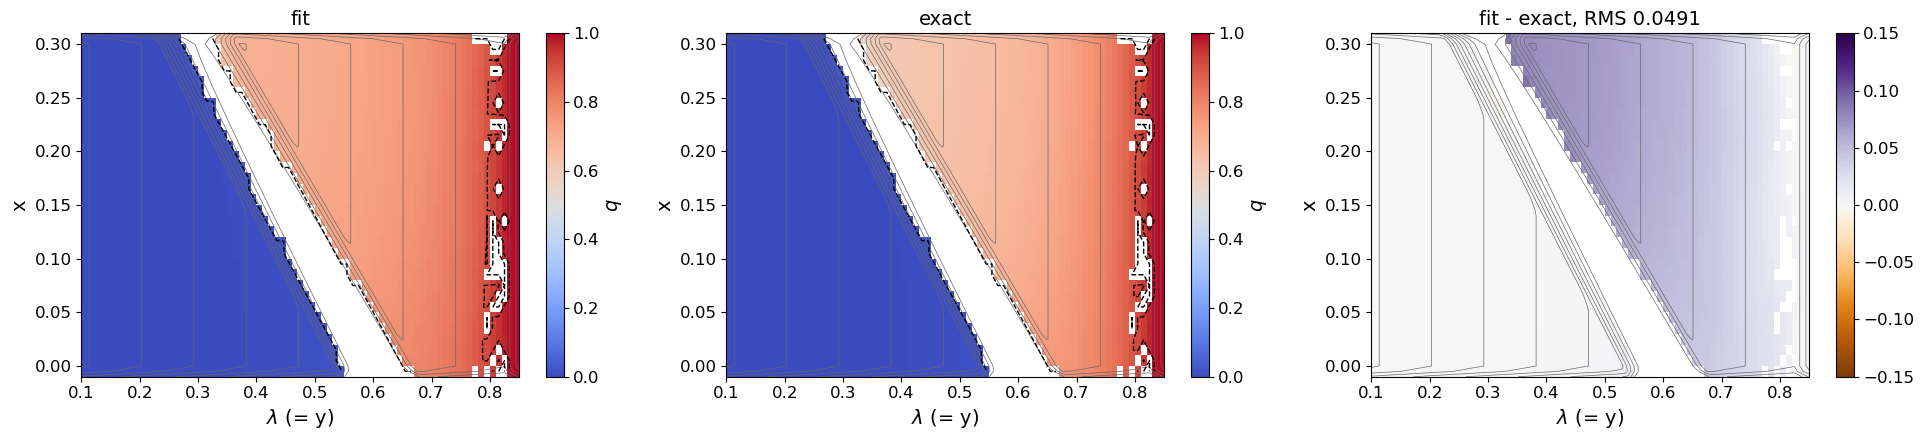

seed 6, 16000 iterations (main: envelope 0.001, gamma 0.1) | RMS(fit - exact) per row, 0.05 < q_exact < 0.95: 0.0618
seed 6: | RMS(fit - exact) per row, 0.05 < q_exact < 0.95: 0.0618


In [11]:
MAX_ITER = 15000                    # iterations per seed (after the warm-up)
SEEDS = [6]
CHUNK = 5000                       # iterations between shown and saved plots
ENVELOPE = 0.001                    # envelope_scale
GAMMA = 0.1                        # regularization strength
WARMUP_ITER = 1000                    # optional warm-up (0 = off)
WARMUP_ENVELOPE = 1
WARMUP_GAMMA = GAMMA
WARMUP_CV = None                   # None: random CV; 0: y only; 1: x only
PLOTS = ('metrics', 'feps', 'obs_pred')

Y = cp.asarray(Z)                  # CVs (y, x) on the GPU once
free = ~(in_a | in_b)

def make_q():
    q = optimalrcs.Committor(
        boundary0=in_a,                # state A
        boundary1=in_b,                # state B
        i_traj=i_traj,                 # excursion
        t_traj=t_traj,                 # saved-row index
    )
    q.set_boundary_traps()             # excursions start/end in A or B: Z_q as for the continuous runs
    return q

# Effective potential (incl. the constant force along y) for the contours
gy, gx = np.linspace(-0.01, 0.91, 185), np.linspace(-0.01, 0.31, 65)
V = np.array([[potential.effective_potential((np.array([a, b]), np.zeros(2))) for b in gx] for a in gy])
lev = np.linspace(np.percentile(V, 1), np.percentile(V, 92), 14)
E_LAM, E_XQ = np.linspace(LAMBDA_A, LAMBDA_B, 76), np.linspace(-0.01, 0.31, 33)
q_map = seed_runs.committor_map(
    [seed_runs.plane(lam, E_LAM, '$\\lambda$ (= y)', xpos, E_XQ, 'x', contours=(gy, gx, V, lev))],
    mask=free, q_ref=q_ref)

trans = free & (q_ref > 0.05) & (q_ref < 0.95)
def report(q):
    r = cp.asnumpy(q.r_traj)
    return f'| RMS(fit - exact) per row, 0.05 < q_exact < 0.95: {np.sqrt(np.mean((r[trans] - q_ref[trans]) ** 2)):.4f}'

results, q = seed_runs.run_seeds(
    optimalrcs, make_q,
    comp_y=lambda: Y[:, np.random.randint(2)],
    fit_kw=dict(ny=6, print_step=500, save_min_delta_zq=False,
                metrics_print=('iter', 'delta_r2', 'max_sd_zq', 'auc', 'delta_x', 'time_elapsed')),
    seeds=SEEDS, max_iter=MAX_ITER, chunk=CHUNK, out_dir=f'{FIG_DIR}/seeds', envelope=ENVELOPE, gamma=GAMMA,
    warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=WARMUP_GAMMA,
    warmup_comp_y=None if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV]),
    plots=PLOTS, plot_options=dict(metrics=['delta_r2', 'max_sd_zq', 'delta_x']),
    extra_plot={'q_map': q_map},
    report=report,
)

### 5b. Alternative: Plain NPq Fit (as in `qq_-Copy1`)

One plain `optimalrcs.Committor` fit, without the seed loop, chunked plots or traps: 2000 iterations with a very wide envelope (`envelope_scale` 10⁶, updates over the whole range of q), then 10000 with `envelope_scale` 0.01, then the standard plots. Run either this cell or the section 5 cell; the sections below use `q` from whichever ran last. (`Committor.fit_transform` has no `delta_r2_max_change_allowed`; that option of `qq_-Copy1` exists only for `CommittorNE`.)

Without `set_boundary_traps()` the fit is the same, but the Z_q plots of `plots_feps` drop towards 0 at large lags: every excursion starts and ends in A or B, and without traps those segment edges count as cuts (notes §8.1). Section 6 makes its Z_q plots with the traps.

In [ ]:
Y = cp.asarray(Z)                  # CVs (y, x) on the GPU
def comp_y():
    return Y[:, np.random.randint(2)]

q = optimalrcs.Committor(boundary0=in_a, boundary1=in_b, i_traj=i_traj, t_traj=t_traj)
np.random.seed(1); cp.random.seed(1)
optimalrcs.envelope_scale = 1000000
q.fit_transform(comp_y, gamma=0.1, max_iter=2000)
optimalrcs.envelope_scale = 0.01
q.fit_transform(comp_y, gamma=0.1, max_iter=10000)

q.plots_feps(delta_t_sim=MD_DT * STRIDE)   # time per saved row
q.plots_obs_pred()
q.plots_obs_pred(log_scale=True)
plt.show()
q_ex = cp.asnumpy(q_ref)
trans = ~(in_a | in_b) & (q_ex > 0.05) & (q_ex < 0.95)
r = cp.asnumpy(q.r_traj)
print(f'RMS(fit - exact) per row, 0.05 < q_exact < 0.95: {np.sqrt(np.mean((r[trans] - q_ex[trans]) ** 2)):.4f}')

## 6. Z_q Against N_AB

Z_q(q, Δt) of the fit and of the exact committor at lags Δt = 1 … 32768 saved rows, with A/B as traps. For the committor every curve is flat in q and converges to `N_AB` (dashed); at short lags the level fluctuates by roughly √N_AB around it. A slope in q or lags that disagree beyond that would show that the RC is not the committor. Without traps (`set_boundary_traps` left out) the curves fall towards 0 at large lags: an artifact of the excursion segments, not of the fit.

In [ ]:
LDT = [2 ** k for k in range(16)]
colors = plt.cm.viridis(np.linspace(0, 0.95, len(LDT)))

def zq_profiles(r):
    qz = make_q()                  # same boundaries, segments and traps
    qz.r_traj = cp.asarray(np.where(in_a, 0.0, np.where(in_b, 1.0, r)))
    out = []
    for dt_ in LDT:
        e, z = cut_profiles.comp_zq(qz.r_traj, qz.b_traj, qz.i_traj, qz.future_boundary, qz.past_boundary, dt=dt_)
        out.append((cp.asnumpy(e)[:-2], cp.asnumpy(z)[:-1]))
    del qz
    return out

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (r, title) in zip(axes, [(cp.asnumpy(q.r_traj), f'NPq (seed {SEEDS[-1]})'), (q_ref, 'exact committor')]):
    for (e, z), dt_, c in zip(zq_profiles(r), LDT, colors):
        ax.plot(e, z, color=c, lw=1.2, label=f'$\\Delta t$ = {dt_}')
    ax.axhline(N_AB, color='k', ls='--', lw=1.2, label=f'$N_{{AB}}$ = {N_AB}')
    ax.set(title=title, xlabel='$q$', ylim=(0, 1.4 * N_AB)); ax.grid(alpha=0.3)
axes[0].set_ylabel('$Z_q$')
axes[1].legend(fontsize=8, ncol=2, frameon=False, loc='lower center')
plt.tight_layout()
save_fig('zq_vs_nab')
plt.show()
cp.get_default_memory_pool().free_all_blocks()

## 7. Committor on the Potential, and a Model-Free Check

Left: the fit against λ for a sample of rows, coloured by the exact committor. Points off the diagonal band at a given colour are where the fit and the exact committor differ. Right: the fitted committor per (λ, x) bin on the effective potential (dashed: q = 0.1, 0.5, 0.9).

**Model-free check.** For every excursion that reaches a band of exact q, the fraction that ends in B (rather than back in A) estimates the committor of the band directly from the data, without any fit. NPq should follow this fraction, also where it differs from the exact committor by more than the error bar (a fluctuation of the finite data).

In [ ]:
r = cp.asnumpy(q.r_traj)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.6]})
show = np.random.default_rng(0).permutation(np.flatnonzero(free))[:200_000]
sc = ax1.scatter(lam[show], r[show], c=q_ref[show], cmap='coolwarm', vmin=0, vmax=1, s=1, edgecolors='none')
fig.colorbar(sc, ax=ax1, label='exact $q$')
ax1.set(xlabel='$\\lambda$ (= y)', ylabel='$q$ (NPq)')

bm = seed_runs.BinnedMean((lam, xpos), (E_LAM, E_XQ), free)
M = bm(r)
im = ax2.pcolormesh(E_LAM, E_XQ, M.T, cmap='coolwarm', vmin=0, vmax=1)
ax2.contour(gy, gx, V.T, levels=lev, colors='0.4', linewidths=0.5)
ax2.contour((E_LAM[1:] + E_LAM[:-1]) / 2, (E_XQ[1:] + E_XQ[:-1]) / 2, np.nan_to_num(M, nan=0.5).T,
            levels=[0.1, 0.5, 0.9], colors='k', linewidths=1, linestyles='--')
ax2.set(xlabel='$\\lambda$ (= y)', ylabel='x', xlim=(LAMBDA_A, LAMBDA_B), ylim=(-0.01, 0.31))
fig.colorbar(im, ax=ax2, label='$q$')
plt.tight_layout()
save_fig('committor')
plt.show()

# outcome of every excursion: does its last row lie in B?
last = np.r_[i_traj[1:] != i_traj[:-1], True]
ends_in_b = np.zeros(i_traj[-1] + 1, bool); ends_in_b[i_traj[last]] = in_b[last]
ends_known = np.zeros(i_traj[-1] + 1, bool); ends_known[i_traj[last]] = in_a[last] | in_b[last]
print('band of exact q | excursions | to B (data)     | NPq at entry | exact at entry')
for lo, hi in ((0.2, 0.4), (0.4, 0.55), (0.55, 0.7), (0.7, 0.85), (0.85, 0.95)):
    m = free & (q_ref > lo) & (q_ref < hi)
    seg, first = np.unique(i_traj[m], return_index=True)
    rows_ = np.flatnonzero(m)[first]           # first row of each excursion in the band
    k = ends_known[seg]
    if k.sum() == 0:
        continue
    f = ends_in_b[seg][k].mean(); se = np.sqrt(f * (1 - f) / k.sum())
    print(f'  {lo:.2f} - {hi:.2f}   | {k.sum():10d} | {f:.3f} +- {se:.3f} | {r[rows_][k].mean():12.3f} | {q_ref[rows_][k].mean():.3f}')

## 8. Save Results

Uncomment to save the committor with the kept rows.

In [ ]:
# np.savez(f'{FIG_DIR}/q_npq_md.npz', q=cp.asnumpy(q.r_traj), q_ref=q_ref, y=lam, x=xpos, seed=seed_md, row=row,
#          i_traj=i_traj, lambda_a=LAMBDA_A, lambda_b=LAMBDA_B, n_ab=N_AB)